In [1]:
import numpy as np

scores_orig = np.array([4.0, 2.0, 0.0])
temperatures = [0.5, 1.0, 2.0]

def softmax_temp(s, T):
    exp_s = np.exp((s - np.max(s)) / T)
    return exp_s / np.sum(exp_s)

print("--- TEMPERATURE EXPERIMENT RESULT ---")
for T in temperatures:
    weights = softmax_temp(scores_orig, T)
    entropy = -np.sum(weights * np.log(weights + 1e-12))
    print(f"T = {T:3.1f} | Weights: {np.round(weights, 4)} | Max Weight: {np.max(weights):.4f} | Entropy: {entropy:.4f}")

--- TEMPERATURE EXPERIMENT RESULT ---
T = 0.5 | Weights: [9.817e-01 1.800e-02 3.000e-04] | Max Weight: 0.9817 | Entropy: 0.0930
T = 1.0 | Weights: [0.8668 0.1173 0.0159] | Max Weight: 0.8668 | Entropy: 0.4411
T = 2.0 | Weights: [0.6652 0.2447 0.09  ] | Max Weight: 0.6652 | Entropy: 0.8324


In [4]:
import numpy as np
def stable_softmax(x, axis=-1):
    x_max = np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x - x_max)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

def scaled_dot_product_attention(Q, K, V):
    """
    Q: (..., N, d_k)
    K: (..., M, d_k)
    V: (..., M, d_v)
    """
    d_k = Q.shape[-1]
    scores = np.matmul(Q, K.swapaxes(-2, -1)) / np.sqrt(d_k)
    attention_weights = stable_softmax(scores, axis=-1)
    context = np.matmul(attention_weights, V)
    return scores, attention_weights, context
x_large = np.array([1000.0, 1001.0, 1002.0])
print("Test numerical stability:")
with np.errstate(all='raise'):
    try:
        print("Softmax thông thường:", np.exp(x_large) / np.sum(np.exp(x_large)))
    except FloatingPointError:
        print("Tràn số xảy ra với np.exp! (Đã bắt được lỗi)")

# Chạy hàm stable_softmax để thấy kết quả chuẩn xác
print("Stable Softmax kết quả:", stable_softmax(x_large))

Test numerical stability:
Tràn số xảy ra với np.exp! (Đã bắt được lỗi)
Stable Softmax kết quả: [0.09003057 0.24472847 0.66524096]


Token           | Score      | Attention Weight
---------------------------------------------
The             | 0.7271     | 0.0393         
movie           | -0.2875    | 0.0143         
was             | -1.2146    | 0.0056         
surprisingly    | 2.3852     | 0.2065         
good            | 3.2646     | 0.4976         
despite         | -0.9603    | 0.0073         
a               | -1.2873    | 0.0052         
very            | 1.9344     | 0.1316         
slow            | 0.7549     | 0.0404         
beginning.      | 1.0084     | 0.0521         


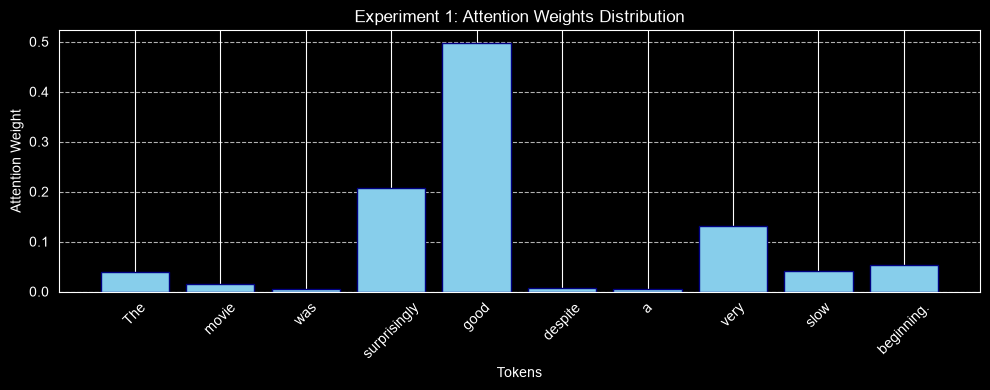

In [5]:
import numpy as np
import matplotlib.pyplot as plt

sentence = "The movie was surprisingly good despite a very slow beginning."
tokens = sentence.split()
T = len(tokens)

# Mô phỏng Query hướng tới sentiment (kích hoạt mạnh ở 'surprisingly', 'good')
np.random.seed(42)
d_k = 16
K_exp1 = np.random.randn(T, d_k)
q_exp1 = np.random.randn(1, d_k)

# Tăng tính tương đồng giả lập cho từ 'good' và 'surprisingly'
q_exp1[0, :4] = [2.0, 2.0, -1.0, 1.0]
K_exp1[tokens.index("good"), :4] = [2.5, 2.0, -1.0, 1.0]
K_exp1[tokens.index("surprisingly"), :4] = [2.0, 1.8, -0.8, 0.9]

scores_e1, weights_e1, _ = scaled_dot_product_attention(q_exp1, K_exp1, K_exp1)
weights_e1 = weights_e1.squeeze()

# In Bảng Phân Bố
print(f"{'Token':<15} | {'Score':<10} | {'Attention Weight':<15}")
print("-" * 45)
for token, score, weight in zip(tokens, scores_e1.squeeze(), weights_e1):
    print(f"{token:<15} | {score:<10.4f} | {weight:<15.4f}")

# Vẽ biểu đồ Bar Chart
plt.figure(figsize=(10, 4))
plt.bar(tokens, weights_e1, color='skyblue', edgecolor='navy')
plt.title("Experiment 1: Attention Weights Distribution")
plt.xlabel("Tokens")
plt.ylabel("Attention Weight")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

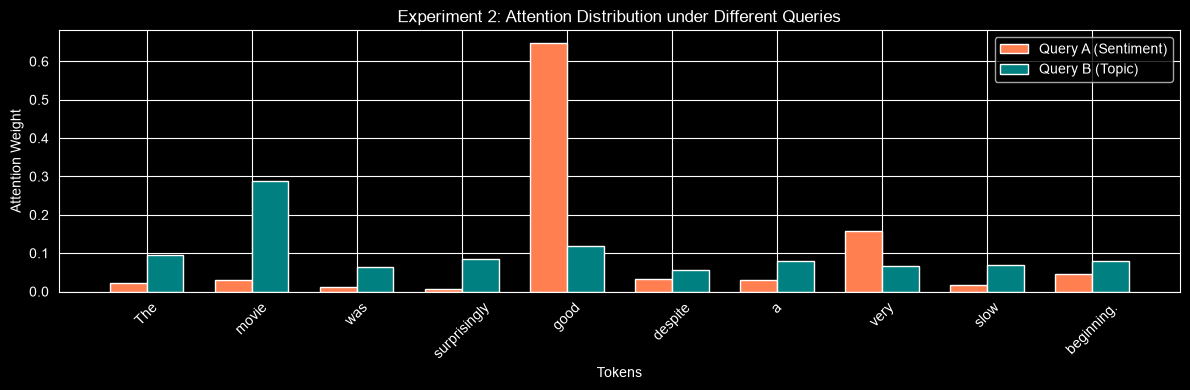

In [6]:
np.random.seed(42)
K_exp2 = np.random.randn(T, d_k)

# Key đặc trưng cho Sentiment vs Aspect
K_exp2[tokens.index("movie"), :] += np.array([3.0] + [0.0]*(d_k-1))
K_exp2[tokens.index("good"), :] += np.array([0.0, 3.0] + [0.0]*(d_k-2))

q_sentiment = np.zeros((1, d_k))
q_sentiment[0, 1] = 3.0  # Tìm tính từ sentiment

q_topic = np.zeros((1, d_k))
q_topic[0, 0] = 3.0      # Tìm danh từ topic

_, w_sentiment, _ = scaled_dot_product_attention(q_sentiment, K_exp2, K_exp2)
_, w_topic, _ = scaled_dot_product_attention(q_topic, K_exp2, K_exp2)

plt.figure(figsize=(12, 4))
x_indices = np.arange(T)
width = 0.35

plt.bar(x_indices - width/2, w_sentiment.squeeze(), width, label='Query A (Sentiment)', color='coral')
plt.bar(x_indices + width/2, w_topic.squeeze(), width, label='Query B (Topic)', color='teal')

plt.xlabel('Tokens')
plt.ylabel('Attention Weight')
plt.title('Experiment 2: Attention Distribution under Different Queries')
plt.xticks(x_indices, tokens, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()